In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
words = open('names.txt').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [3]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0

itos = {i:s for s, i in stoi.items()}

vocab_size = len(itos)
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [4]:
# build dataset
# training split, dev/validation split, test split
# 80%, 10%, 10%
block_size = 3

def build_dataset(words):
    X, Y = [], []

    for w in words:
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            # print(''.join(itos[i] for i in context), '--->', itos[ix])
            context = context[1:] + [ix]

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

import random

random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

torch.Size([182400, 3]) torch.Size([182400])
torch.Size([22877, 3]) torch.Size([22877])
torch.Size([22869, 3]) torch.Size([22869])


In [29]:
n_embd = 10
n_hidden = 200

C = torch.randn((vocab_size, n_embd))
W1 = torch.randn((n_embd * block_size, n_hidden)) * 0.2
b1 = torch.randn(n_hidden) * 0.01
W2 = torch.randn((n_hidden, vocab_size)) * 0.01
b2 = torch.randn(vocab_size) * 0
parameters = [C, W1, b1, W2, b2]

print(sum(p.nelement() for p in parameters))

for p in parameters:
    p.requires_grad = True

11897


In [30]:
max_steps = 200000
batch_size = 32
lossi = []

for i in range(200000):
    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,))
    Xb, Yb = Xtr[ix], Ytr[ix]
    # forward pass
    emb = C[Xb] # embed the characters into vectors
    embcat = emb.view(emb.shape[0], -1) # concatenate the vectors
    hpreact = embcat @ W1 + b1 # hidden layer pre-activation
    h = torch.tanh(hpreact) # hidden layer
    logits = h @ W2 + b2 # output layer
    loss = F.cross_entropy(logits, Yb) # loss function

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.01 if i < 100000 else 0.01 # step learning rate decay
    for p in parameters:
        p.data += -lr * p.grad

    # lri.append(lre[i])
    if i % 10000 == 0:
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())
    # break

      0/ 200000: 3.3050
  10000/ 200000: 2.3184
  20000/ 200000: 2.3980
  30000/ 200000: 1.9517
  40000/ 200000: 2.0533
  50000/ 200000: 2.1242
  60000/ 200000: 2.0592
  70000/ 200000: 2.4280
  80000/ 200000: 2.0197
  90000/ 200000: 2.2420
 100000/ 200000: 2.5628
 110000/ 200000: 2.2956
 120000/ 200000: 2.0717
 130000/ 200000: 1.9239
 140000/ 200000: 1.7641
 150000/ 200000: 2.5427
 160000/ 200000: 1.9757
 170000/ 200000: 2.4305
 180000/ 200000: 2.0777
 190000/ 200000: 1.8230


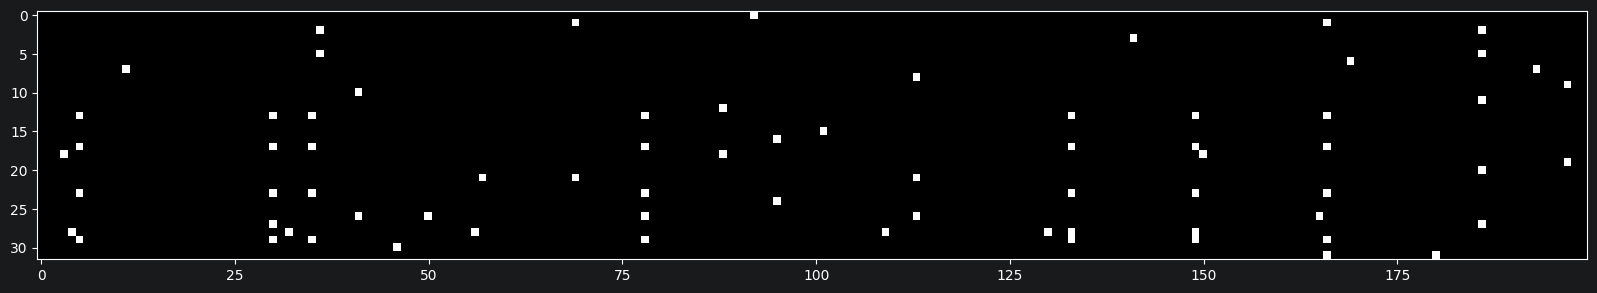

In [26]:
plt.figure(figsize=(20, 10))
plt.imshow(h.abs() > 0.99, cmap='gray', interpolation='nearest')

(array([198., 158., 190., 161., 156., 164., 159., 120., 136., 128., 135.,
        132., 103.,  86., 109.,  93., 117., 111.,  70., 102., 104.,  91.,
        106., 101.,  97.,  95.,  97.,  84., 103.,  88., 128., 121.,  78.,
        132., 100., 125.,  88., 121., 119., 114., 130., 150., 121., 132.,
        160., 198., 179., 195., 201., 214.]),
 array([-9.98906493e-01, -9.58947453e-01, -9.18988414e-01, -8.79029374e-01,
        -8.39070334e-01, -7.99111295e-01, -7.59152255e-01, -7.19193215e-01,
        -6.79234176e-01, -6.39275136e-01, -5.99316096e-01, -5.59357057e-01,
        -5.19398017e-01, -4.79438977e-01, -4.39479938e-01, -3.99520898e-01,
        -3.59561858e-01, -3.19602818e-01, -2.79643779e-01, -2.39684739e-01,
        -1.99725699e-01, -1.59766660e-01, -1.19807620e-01, -7.98485804e-02,
        -3.98895407e-02,  6.94990158e-05,  4.00285387e-02,  7.99875784e-02,
         1.19946618e-01,  1.59905658e-01,  1.99864697e-01,  2.39823737e-01,
         2.79782777e-01,  3.19741817e-01,  3.59700

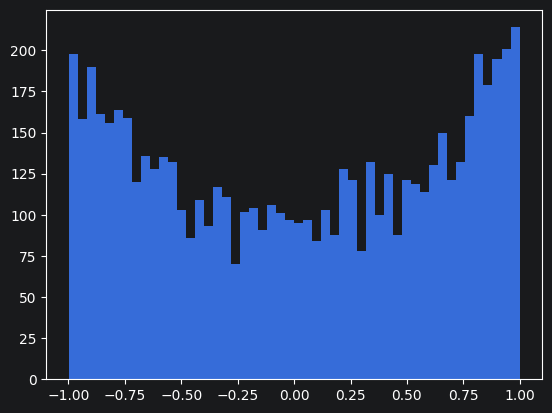

In [27]:
plt.hist(h.view(-1).tolist(), 50)

(array([  4.,   6.,   1.,   2.,   4.,   7.,   8.,  11.,  19.,  34.,  50.,
         47.,  50.,  79., 104., 161., 169., 202., 271., 282., 331., 301.,
        338., 347., 379., 344., 382., 376., 308., 303., 259., 227., 235.,
        165., 152., 100.,  95.,  62.,  57.,  38.,  33.,  18.,   9.,   6.,
          8.,   6.,   4.,   1.,   0.,   5.]),
 array([-3.75548434, -3.60390504, -3.45232574, -3.30074645, -3.14916715,
        -2.99758785, -2.84600855, -2.69442925, -2.54284995, -2.39127065,
        -2.23969135, -2.08811205, -1.93653275, -1.78495346, -1.63337416,
        -1.48179486, -1.33021556, -1.17863626, -1.02705696, -0.87547766,
        -0.72389836, -0.57231906, -0.42073977, -0.26916047, -0.11758117,
         0.03399813,  0.18557743,  0.33715673,  0.48873603,  0.64031533,
         0.79189463,  0.94347393,  1.09505322,  1.24663252,  1.39821182,
         1.54979112,  1.70137042,  1.85294972,  2.00452902,  2.15610832,
         2.30768762,  2.45926692,  2.61084621,  2.76242551,  2.91400481,
 

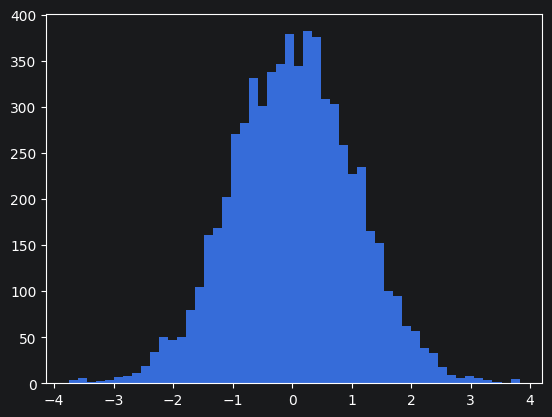

In [28]:
plt.hist(hpreact.view(-1).tolist(), 50)

In [10]:
-torch.tensor(1/27.0).log()

tensor(3.2958)

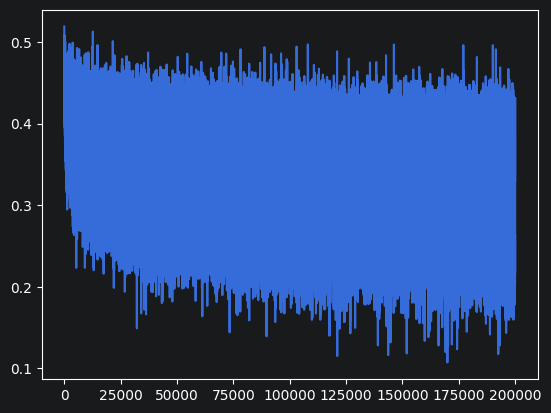

In [31]:
plt.plot(lossi)

In [32]:
@torch.no_grad()
def split_loss(split):
    x, y = {
        'train': (Xtr, Ytr),
        'val': (Xdev, Ydev),
        'test': (Xte, Yte),
    }[split]
    emb = C[x] # (N, block_size, n_emb)
    embcat = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
    h = torch.tanh(embcat @ W1 + b1)
    logits = h @ W2 + b2 # (N, vocab_size)
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.0982837677001953
val 2.132380962371826


In [33]:
for _ in range(20):

    out = []
    context = [0] * block_size # initialize with all ...
    while True:
        # forward pass the neural net
        emb = C[torch.tensor([context])] # (1,block_size,n_embd)
        h = torch.tanh(emb.view(1, -1) @ W1 + b1)
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1)
        # sample from the distribution
        ix = torch.multinomial(probs, num_samples=1).item()
        # shift the context window and track the samples
        context = context[1:] + [ix]
        out.append(ix)
        # if we sample the special '.' token, break
        if ix == 0:
            break

    print(''.join(itos[i] for i in out))

evarne.
cerivencinsleigh.
kalay.
amargjagreahmaheem.
malis.
saira.
son.
alavel.
graceiah.
jaquinn.
hon.
gradysli.
roden.
rou.
liviani.
cyra.
khalin.
ina.
rumia.
davianahton.
